# 🚗 Automobile Exploratory Data Analysis (EDA): Statistical Testing, Visualization & Feature Discovery
**IBM Data Science Practical Review & Comprehensive Diagnostic Guide**

---

### 📋 Overview & Learning Objectives
Exploratory Data Analysis (EDA) is the foundational phase of data science where we uncover structural patterns, evaluate feature-target relationships, detect anomalies, test statistical hypotheses, and identify the most predictive attributes before fitting machine learning models.

By the end of this reviewed and extended notebook, you will master:
1. **Visual Pattern Analysis**: Continuous variables (regression plots with confidence intervals) and categorical variables (box plots with quartile distributions).
2. **Descriptive Statistics & Value Counts**: 5-number summaries, skewness, spread, and detecting extreme class imbalances (e.g. rear-engine vehicles).
3. **Multi-Variable Grouping & Pivot Heatmaps**: Aggregating pricing by multi-level categorical combinations (`drive-wheels` and `body-style`) with annotated heatmaps.
4. **Correlation & Causation**: Quantifying linear association using **Pearson correlation coefficients ($r$)** and assessing statistical significance using two-tailed **$p$-values**.
5. **Analysis of Variance (ANOVA)**: Testing whether price differences across categorical groups (`drive-wheels`, `body-style`, `engine-location`) are statistically significant using the $F$-test.
6. **Automated Unit Testing & Quality Assurance**: 5 programmatic assertion tests ensuring data integrity, statistical bounds, and calculation validity.
7. **Downstream Feature Selection**: Prioritizing key variables for predictive modeling (SLR, MLR, and Polynomial Regression).

---


### 📑 Table of Contents
- [0. Environment Setup & Data Loading](#sec-0)
- [1. Visualizing Individual Feature Patterns](#sec-1)
  - [1.1 Positive Linear Relationships (engine-size, curb-weight, horsepower)](#sec-1-1)
  - [1.2 Negative Linear Relationships (highway-mpg, city-mpg)](#sec-1-2)
  - [1.3 Weak Linear Relationships (peak-rpm, stroke)](#sec-1-3)
  - [1.4 Categorical Variables (body-style, engine-location, drive-wheels)](#sec-1-4)
- [2. Descriptive Statistical Analysis](#sec-2)
  - [2.1 Numerical Summaries & Distribution Metrics](#sec-2-1)
  - [2.2 Categorical Value Counts & Class Imbalance](#sec-2-2)
- [3. Grouping, Pivot Tables & Visual Heatmaps](#sec-3)
  - [3.1 Aggregating Price by drive-wheels and body-style](#sec-3-1)
  - [3.2 Pivot Table Construction](#sec-3-2)
  - [3.3 Modern Seaborn Heatmap Visualization](#sec-3-3)
- [4. Correlation Analysis: Pearson r & p-Values](#sec-4)
  - [4.1 Theoretical Framework & p-Value Interpretation](#sec-4-1)
  - [4.2 Systematic Feature-by-Feature Pearson Hypothesis Tests](#sec-4-2)
  - [4.3 Consolidated Correlation Ranking Table](#sec-4-3)
- [5. Analysis of Variance (ANOVA) for Categorical Features (NEW)](#sec-5)
  - [5.1 ANOVA Theory & The F-Distribution](#sec-5-1)
  - [5.2 Drive Wheels ANOVA & Pairwise Sub-group Tests](#sec-5-2)
  - [5.3 Body Style ANOVA](#sec-5-3)
  - [5.4 Engine Location ANOVA](#sec-5-4)
  - [5.5 Consolidated ANOVA Summary Table](#sec-5-5)
- [6. Automated Unit Tests & Sanity Checks (NEW)](#sec-6)
- [7. Executive Summary & Feature Importance Matrix for Modeling](#sec-7)


<a id="sec-0"></a>
## 0. Environment Setup & Data Loading

We import Python's primary data science stack (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`).

> ⚙️ **Universal Compatibility Note:**
> The original lab used `piplite` and `pyodide.http`, which fail in standard Python / VS Code / Jupyter / Colab environments. The cell below provides universal loading: reading `automobileEDA.csv` locally if present, downloading via standard Python HTTP requests if missing, and preventing any browser environment lock-in.


In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure visualization aesthetics
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
sns.set_theme(style="whitegrid", palette="muted")

print("All scientific libraries imported successfully!")


All scientific libraries imported successfully!


### Load and Audit the Dataset
We load `automobileEDA.csv`, containing 201 cleaned records of vehicle specifications and market prices.


In [2]:
data_filename = "automobileEDA.csv"
data_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/automobileEDA.csv"

if not os.path.exists(data_filename):
    print(f"Downloading {data_filename}...")
    try:
        urllib.request.urlretrieve(data_url, data_filename)
        print("Download successful.")
    except Exception as e:
        print(f"Fallback direct pandas read ({e})...")
        df = pd.read_csv(data_url)
        df.to_csv(data_filename, index=False)
else:
    print(f"Loading local dataset '{data_filename}'...")

df = pd.read_csv(data_filename)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)


Loading local dataset 'automobileEDA.csv'...
Dataset Dimensions: 201 rows, 29 columns


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


### Data Types & Missing Value Audit
Understanding data types is essential:
- **Continuous numerical variables** (`float64`, `int64`) are best analyzed using scatter plots, regression plots, and Pearson correlation.
- **Categorical variables** (`object`) are best analyzed using box plots, frequency counts, groupby aggregations, and ANOVA.


In [3]:
# Audit column data types and missing values
null_counts = df.isnull().sum()
cols_with_nulls = null_counts[null_counts > 0]

print("--- Missing Values Audit ---")
if len(cols_with_nulls) == 0:
    print("Zero missing values across all columns.")
else:
    print(f"Columns with nulls:\n{cols_with_nulls}")

# Count data types
print("\n--- Data Type Distribution ---")
print(df.dtypes.value_counts())


--- Missing Values Audit ---
Columns with nulls:
stroke               4
horsepower-binned    1
dtype: int64

--- Data Type Distribution ---
float64    11
str        10
int64       8
Name: count, dtype: int64


<a id="sec-1"></a>
## 1. Visualizing Individual Feature Patterns

Visualization allows us to immediately identify whether a feature shares a linear, non-linear, or negligible relationship with `price`.

---

<a id="sec-1-1"></a>
### 1.1 Positive Linear Relationships

When the regression line slopes upwards from left to right, increases in the predictor are associated with increases in vehicle price.
Let's examine `engine-size`, `curb-weight`, and `horsepower`.


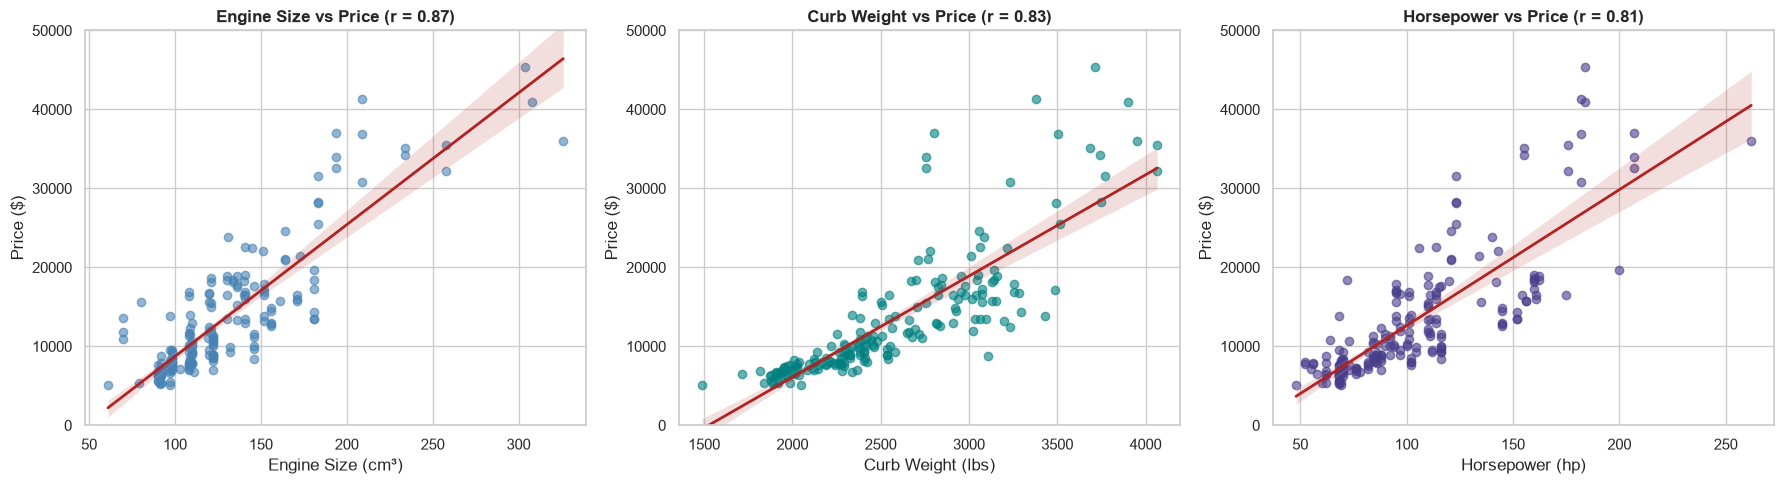

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Engine Size vs Price
sns.regplot(x="engine-size", y="price", data=df, ax=axes[0],
            scatter_kws={'alpha': 0.6, 'color': 'steelblue'},
            line_kws={'color': 'firebrick', 'linewidth': 2})
axes[0].set_title(f"Engine Size vs Price (r = {df[['engine-size', 'price']].corr().iloc[0,1]:.2f})", fontweight='bold')
axes[0].set_xlabel("Engine Size (cm³)")
axes[0].set_ylabel("Price ($)")
axes[0].set_ylim(0, 50000)

# 2. Curb Weight vs Price
sns.regplot(x="curb-weight", y="price", data=df, ax=axes[1],
            scatter_kws={'alpha': 0.6, 'color': 'teal'},
            line_kws={'color': 'firebrick', 'linewidth': 2})
axes[1].set_title(f"Curb Weight vs Price (r = {df[['curb-weight', 'price']].corr().iloc[0,1]:.2f})", fontweight='bold')
axes[1].set_xlabel("Curb Weight (lbs)")
axes[1].set_ylabel("Price ($)")
axes[1].set_ylim(0, 50000)

# 3. Horsepower vs Price
sns.regplot(x="horsepower", y="price", data=df, ax=axes[2],
            scatter_kws={'alpha': 0.6, 'color': 'darkslateblue'},
            line_kws={'color': 'firebrick', 'linewidth': 2})
axes[2].set_title(f"Horsepower vs Price (r = {df[['horsepower', 'price']].corr().iloc[0,1]:.2f})", fontweight='bold')
axes[2].set_xlabel("Horsepower (hp)")
axes[2].set_ylabel("Price ($)")
axes[2].set_ylim(0, 50000)

plt.tight_layout()
plt.show()


#### 📝 Visual Interpretation (Positive Linear Predictors):
- `engine-size` ($r \approx 0.87$), `curb-weight` ($r \approx 0.83$), and `horsepower` ($r \approx 0.81$) all exhibit steep positive linear slopes.
- As engine capacity and vehicle mass grow, vehicle production costs and market prestige rise correspondingly. These three features are excellent candidate predictors for regression modeling.

---

<a id="sec-1-2"></a>
### 1.2 Negative Linear Relationships

When the regression line slopes downward from left to right, higher feature values correspond to lower vehicle prices.
Let's inspect fuel efficiency: `highway-mpg` and `city-mpg`.


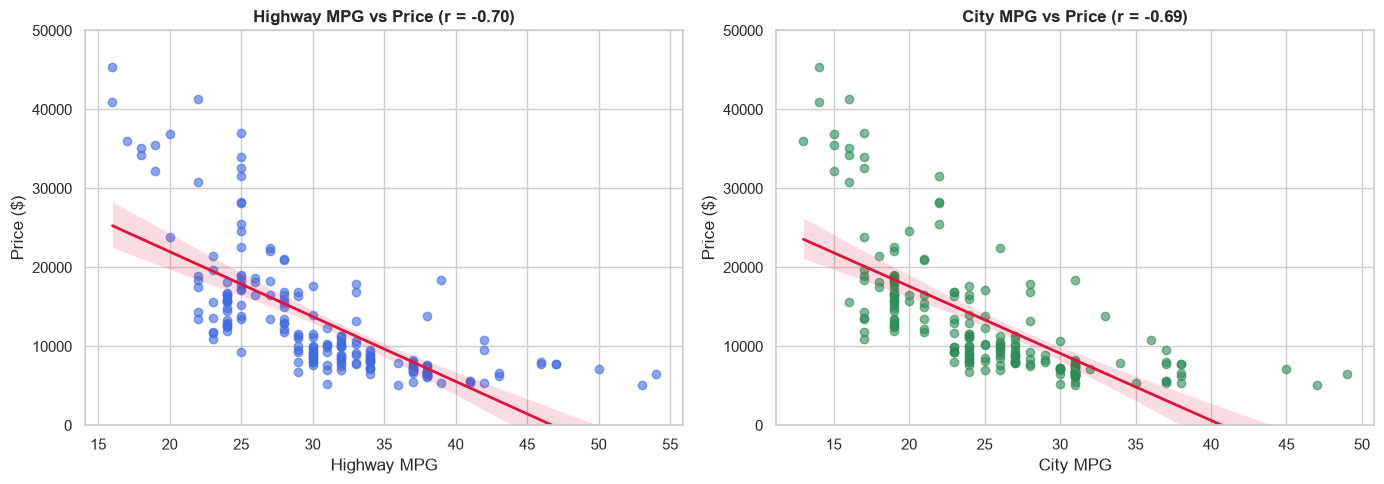

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Highway MPG vs Price
sns.regplot(x="highway-mpg", y="price", data=df, ax=axes[0],
            scatter_kws={'alpha': 0.6, 'color': 'royalblue'},
            line_kws={'color': 'crimson', 'linewidth': 2})
axes[0].set_title(f"Highway MPG vs Price (r = {df[['highway-mpg', 'price']].corr().iloc[0,1]:.2f})", fontweight='bold')
axes[0].set_xlabel("Highway MPG")
axes[0].set_ylabel("Price ($)")
axes[0].set_ylim(0, 50000)

# City MPG vs Price
sns.regplot(x="city-mpg", y="price", data=df, ax=axes[1],
            scatter_kws={'alpha': 0.6, 'color': 'seagreen'},
            line_kws={'color': 'crimson', 'linewidth': 2})
axes[1].set_title(f"City MPG vs Price (r = {df[['city-mpg', 'price']].corr().iloc[0,1]:.2f})", fontweight='bold')
axes[1].set_xlabel("City MPG")
axes[1].set_ylabel("Price ($)")
axes[1].set_ylim(0, 50000)

plt.tight_layout()
plt.show()


#### 📝 Visual Interpretation (Fuel Efficiency):
- Both `highway-mpg` ($r \approx -0.70$) and `city-mpg` ($r \approx -0.69$) exhibit strong negative relationships with car price.
- Economy vehicles prioritize high miles per gallon, whereas luxury sedans and high-performance sports cars sacrifice fuel efficiency for powerful engines and heavier chassis.

---

<a id="sec-1-3"></a>
### 1.3 Weak Linear Relationships

A nearly horizontal regression line indicates that knowing the feature value gives virtually no information about vehicle price.
Let's evaluate `peak-rpm` and `stroke`.


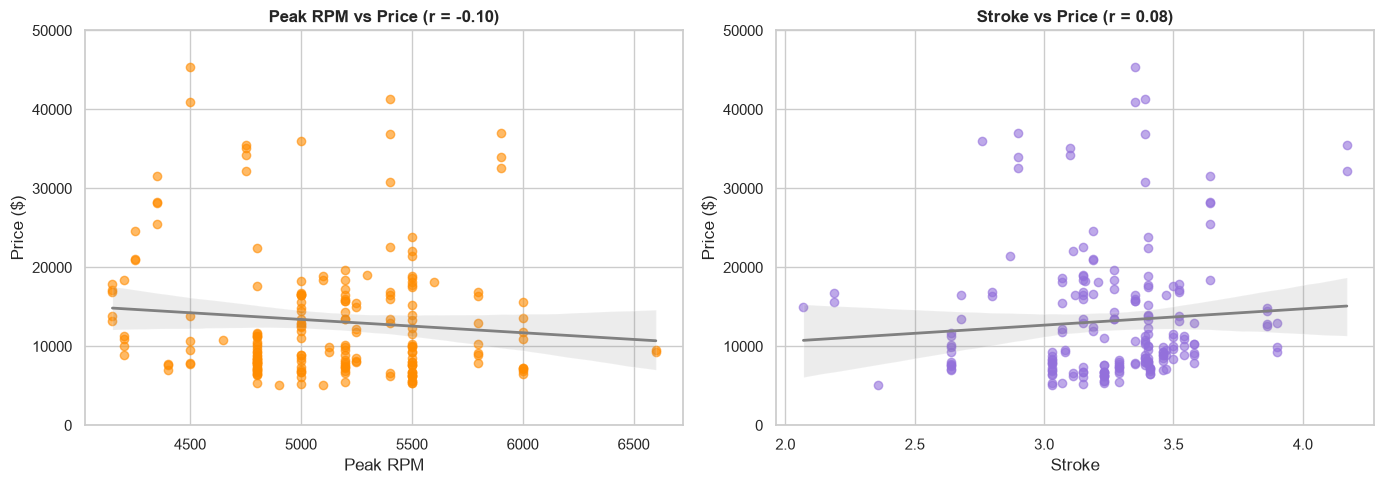

Weak Relationship Summary:
  peak-rpm vs price corr: -0.1016
  stroke vs price corr:   0.0823


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Peak RPM vs Price
sns.regplot(x="peak-rpm", y="price", data=df, ax=axes[0],
            scatter_kws={'alpha': 0.6, 'color': 'darkorange'},
            line_kws={'color': 'gray', 'linewidth': 2})
axes[0].set_title(f"Peak RPM vs Price (r = {df[['peak-rpm', 'price']].corr().iloc[0,1]:.2f})", fontweight='bold')
axes[0].set_xlabel("Peak RPM")
axes[0].set_ylabel("Price ($)")
axes[0].set_ylim(0, 50000)

# 2. Stroke vs Price
clean_stroke = df[['stroke', 'price']].dropna()
sns.regplot(x="stroke", y="price", data=clean_stroke, ax=axes[1],
            scatter_kws={'alpha': 0.6, 'color': 'mediumpurple'},
            line_kws={'color': 'gray', 'linewidth': 2})
axes[1].set_title(f"Stroke vs Price (r = {clean_stroke.corr().iloc[0,1]:.2f})", fontweight='bold')
axes[1].set_xlabel("Stroke")
axes[1].set_ylabel("Price ($)")
axes[1].set_ylim(0, 50000)

plt.tight_layout()
plt.show()

print("Weak Relationship Summary:")
print(f"  peak-rpm vs price corr: {df[['peak-rpm', 'price']].corr().iloc[0,1]:.4f}")
print(f"  stroke vs price corr:   {clean_stroke.corr().iloc[0,1]:.4f}")


#### 📝 Key Finding:
- `peak-rpm` ($r = -0.10$) and `stroke` ($r = 0.08$) have near-zero correlation with price. The regression line is virtually flat, and data points are widely scattered. Neither variable is an effective linear predictor of price.

---

<a id="sec-1-4"></a>
### 1.4 Categorical Variables: Box Plot Distributions

For categorical variables (such as `body-style`, `engine-location`, and `drive-wheels`), box plots visualize:
- Median (center line inside the box)
- Interquartile Range (IQR, between 25th and 75th percentiles)
- Whiskers ($1.5 \times \text{IQR}$) and potential outliers.

> 🔍 **Diagnostic Rule for Box Plots:**
> If the box plots for different categories overlap substantially, the categorical variable cannot reliably distinguish price tiers. If distributions are distinct and separated, the feature is a strong candidate predictor.


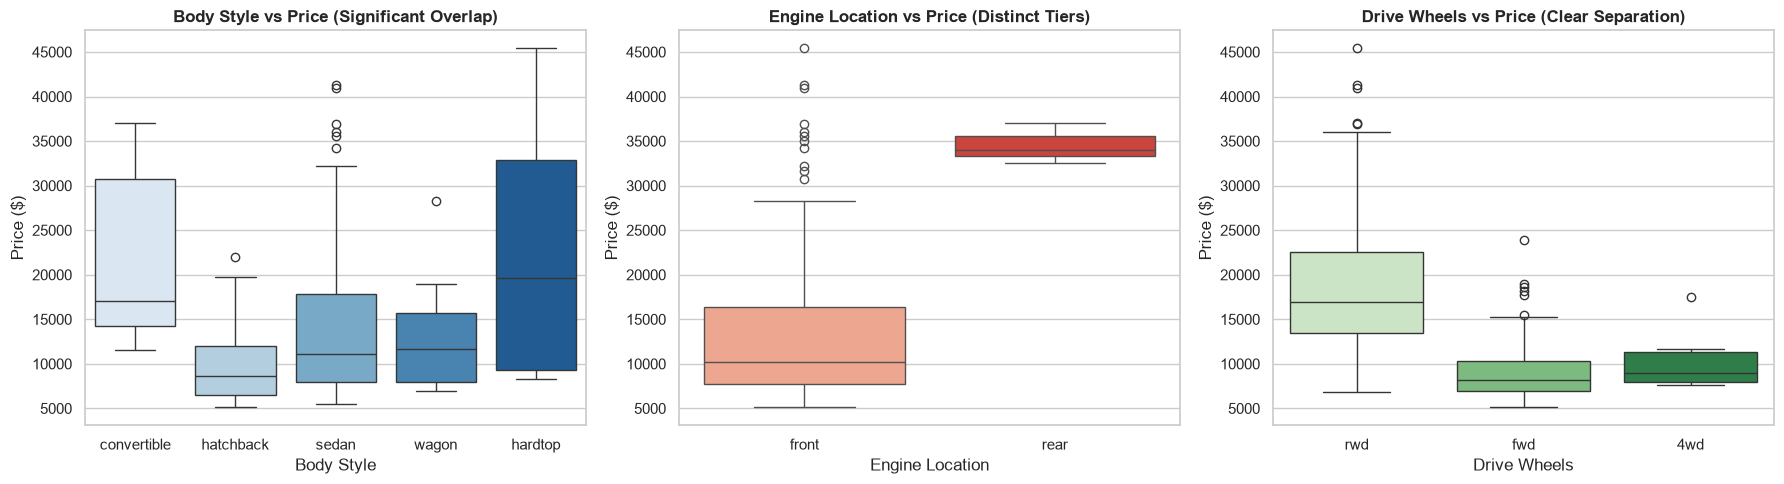

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Body Style vs Price
sns.boxplot(x="body-style", y="price", data=df, hue="body-style", palette="Blues", legend=False, ax=axes[0])
axes[0].set_title("Body Style vs Price (Significant Overlap)", fontweight='bold')
axes[0].set_xlabel("Body Style")
axes[0].set_ylabel("Price ($)")

# 2. Engine Location vs Price
sns.boxplot(x="engine-location", y="price", data=df, hue="engine-location", palette="Reds", legend=False, ax=axes[1])
axes[1].set_title("Engine Location vs Price (Distinct Tiers)", fontweight='bold')
axes[1].set_xlabel("Engine Location")
axes[1].set_ylabel("Price ($)")

# 3. Drive Wheels vs Price
sns.boxplot(x="drive-wheels", y="price", data=df, hue="drive-wheels", palette="Greens", legend=False, ax=axes[2])
axes[2].set_title("Drive Wheels vs Price (Clear Separation)", fontweight='bold')
axes[2].set_xlabel("Drive Wheels")
axes[2].set_ylabel("Price ($)")

plt.tight_layout()
plt.show()


#### 📝 Box Plot Findings:
1. **`body-style`**: The price distributions across convertibles, hardtops, hatchbacks, sedans, and wagons overlap significantly. While convertibles and hardtops tend to be pricier, `body-style` alone is not a decisive separator.
2. **`engine-location`**: Rear-engine cars are distinctively positioned in the luxury bracket ($> \$30,000$). However, as we will see in Section 2, only 3 cars in the entire dataset have rear engines!
3. **`drive-wheels`**: Rear-Wheel Drive (`rwd`) vehicles command substantially higher prices than Front-Wheel Drive (`fwd`) or Four-Wheel Drive (`4wd`), with distinct median lines. This makes `drive-wheels` a strong categorical predictor.

---

<a id="sec-2"></a>
## 2. Descriptive Statistical Analysis

<a id="sec-2-1"></a>
### 2.1 Numerical Summaries & Distribution Metrics
We examine the 5-number summary (minimum, Q1, median, Q3, maximum) along with mean, standard deviation, and count for continuous features.


In [8]:
# Numerical descriptive statistics
df.describe().round(2)


,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
count,201.00,201.0,201.00,201.00,201.00,201.00,201.00,201.00,201.00,197.00,201.00,201.00,201.00,201.00,201.00,201.00,201.00,201.0,201.0
mean,0.84,122.0,98.80,0.84,0.92,53.77,2555.67,126.88,3.33,3.26,10.16,103.41,5117.67,25.18,30.69,13207.13,9.94,0.1,0.9
std,1.25,32.0,6.07,0.06,0.03,2.45,517.30,41.55,0.27,0.32,4.00,37.37,478.11,6.42,6.82,7947.07,2.53,0.3,0.3
min,-2.00,65.0,86.60,0.68,0.84,47.80,1488.00,61.00,2.54,2.07,7.00,48.00,4150.00,13.00,16.00,5118.00,4.80,0.0,0.0
25%,0.00,101.0,94.50,0.80,0.89,52.00,2169.00,98.00,3.15,3.11,8.60,70.00,4800.00,19.00,25.00,7775.00,7.83,0.0,1.0
50%,1.00,122.0,97.00,0.83,0.91,54.10,2414.00,120.00,3.31,3.29,9.00,95.00,5125.37,24.00,30.00,10295.00,9.79,0.0,1.0
75%,2.00,137.0,102.40,0.88,0.92,55.50,2926.00,141.00,3.58,3.41,9.40,116.00,5500.00,30.00,34.00,16500.00,12.37,0.0,1.0
max,3.00,256.0,120.90,1.00,1.00,59.80,4066.00,326.00,3.94,4.17,23.00,262.00,6600.00,49.00,54.00,45400.00,18.08,1.0,1.0


In [9]:
# Categorical descriptive statistics
df.describe(include=['object'])


C:\Users\MSoubhi\AppData\Local\Temp\ipykernel_27244\2452437290.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['object'])


,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system,horsepower-binned
count,201,201,201,201,201,201,201,201,201,200
unique,22,2,2,5,3,2,6,7,8,3
top,toyota,std,four,sedan,fwd,front,ohc,four,mpfi,Low
freq,32,165,115,94,118,198,145,157,92,115


<a id="sec-2-2"></a>
### 2.2 Categorical Value Counts & Class Imbalance Analysis

Checking category frequencies reveals whether subgroups have sufficient sample size to support reliable statistical inference.


In [10]:
# 1. Drive Wheels Frequency Table
drive_wheels_counts = df['drive-wheels'].value_counts().to_frame()
drive_wheels_counts.rename(columns={'count': 'value_counts'}, inplace=True)
drive_wheels_counts['percentage (%)'] = (drive_wheels_counts['value_counts'] / len(df) * 100).round(1)
drive_wheels_counts.index.name = 'drive-wheels'

print("--- Drive Wheels Value Counts ---")
display(drive_wheels_counts)

# 2. Engine Location Frequency Table
engine_loc_counts = df['engine-location'].value_counts().to_frame()
engine_loc_counts.rename(columns={'count': 'value_counts'}, inplace=True)
engine_loc_counts['percentage (%)'] = (engine_loc_counts['value_counts'] / len(df) * 100).round(1)
engine_loc_counts.index.name = 'engine-location'

print("\n--- Engine Location Value Counts ---")
display(engine_loc_counts)


--- Drive Wheels Value Counts ---


,value_counts,percentage (%)
drive-wheels,,
fwd,118,58.7
rwd,75,37.3
4wd,8,4.0



--- Engine Location Value Counts ---


,value_counts,percentage (%)
engine-location,,
front,198,98.5
rear,3,1.5


#### ⚠️ Critical Analytical Finding (Extreme Class Imbalance):
- **`engine-location`**: 198 cars have front engines, while only **3 cars** have rear engines (just 1.5% of the dataset!).
  > 🚨 **Statistical Implication:**
  > Although rear-engine cars had higher prices in the box plot, this result is drawn from a tiny sample of 3 vehicles (primarily Porsche 911s). Drawing broad statistical conclusions or training a machine learning model on such an extreme imbalance is prone to high variance and bias.
- **`drive-wheels`**: Features a healthy distribution (118 FWD, 75 RWD, 8 4WD), making it a much more robust predictor.

---

<a id="sec-3"></a>
## 3. Grouping, Pivot Tables & Visual Heatmaps

<a id="sec-3-1"></a>
### 3.1 Aggregating Price by `drive-wheels` and `body-style`
We group the data by drive wheels and body style to examine average prices across categorical intersections.


In [11]:
# Group by drive-wheels and body-style, then calculate mean price
df_group_one = df[['drive-wheels', 'body-style', 'price']]
grouped_results = df_group_one.groupby(['drive-wheels', 'body-style'], as_index=False).mean()
grouped_results.rename(columns={'price': 'mean_price'}, inplace=True)
grouped_results['mean_price'] = grouped_results['mean_price'].round(2)

print("Average Price by Drive-Wheels and Body-Style:")
display(grouped_results)


Average Price by Drive-Wheels and Body-Style:


,drive-wheels,body-style,mean_price
0,4wd,hatchback,7603.00
1,4wd,sedan,12647.33
2,4wd,wagon,9095.75
3,fwd,convertible,11595.00
4,fwd,hardtop,8249.00
5,fwd,hatchback,8396.39
6,fwd,sedan,9811.80
7,fwd,wagon,9997.33
8,rwd,convertible,23949.60
9,rwd,hardtop,24202.71


<a id="sec-3-2"></a>
### 3.2 Pivot Table Construction
A pivot table formats the grouped data into a 2D matrix, where rows represent `drive-wheels` and columns represent `body-style`.


In [12]:
grouped_pivot = grouped_results.pivot(index='drive-wheels', columns='body-style', values='mean_price')
# Fill missing cell combinations (e.g. 4wd convertible does not exist) with 0
grouped_pivot_filled = grouped_pivot.fillna(0)

print("Pivot Table (Mean Price in $):")
display(grouped_pivot_filled.round(2))


Pivot Table (Mean Price in $):


body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,0.0,0.00,7603.00,12647.33,9095.75
fwd,11595.0,8249.00,8396.39,9811.80,9997.33
rwd,23949.6,24202.71,14337.78,21711.83,16994.22


<a id="sec-3-3"></a>
### 3.3 Modern Seaborn Heatmap Visualization
The original lab used basic `plt.pcolor`. Here we use `sns.heatmap` with cell price annotations and formatted axes for superior presentation readability.


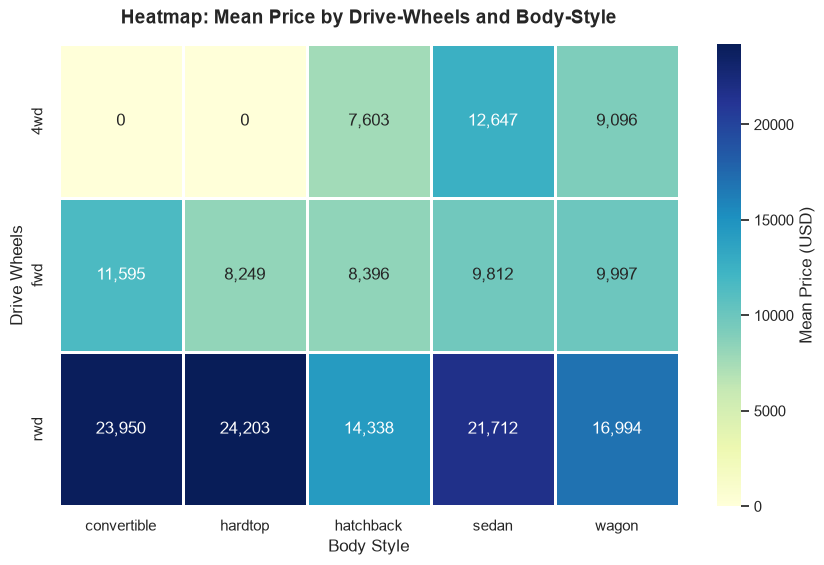

In [13]:
plt.figure(figsize=(10, 6))
sns.heatmap(grouped_pivot_filled, annot=True, fmt=',.0f', cmap='YlGnBu', 
            cbar_kws={'label': 'Mean Price (USD)'}, linewidths=1, linecolor='white')

plt.title("Heatmap: Mean Price by Drive-Wheels and Body-Style", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Body Style", fontsize=12)
plt.ylabel("Drive Wheels", fontsize=12)
plt.show()


#### 📝 Heatmap Takeaways:
- **Rear-Wheel Drive (RWD) Convertibles and Hardtops** command the highest market prices (averaging over $\$23,000 - \$24,000$).
- **Front-Wheel Drive (FWD) Hatchbacks** occupy the lowest price tier (averaging $\approx \$7,975$).
- The combination of drive drivetrain and body form factor reveals clear market segment pricing tiers.

---

<a id="sec-4"></a>
## 4. Correlation Analysis: Pearson r & p-Values

<a id="sec-4-1"></a>
### 4.1 Theoretical Framework & p-Value Interpretation

**Pearson Correlation ($r$)** measures the linear dependence between two continuous variables:
$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

- **$r = +1$:** Perfect positive linear relationship.
- **$r = 0$:** No linear relationship.
- **$r = -1$:** Perfect negative linear relationship.

**The $P$-value** tests the null hypothesis ($H_0$) that the true population correlation is zero:
- **$p < 0.001$:** **Strong evidence** that the correlation is statistically significant (denoted with `***`).
- **$p < 0.05$:** **Moderate evidence** of statistical significance (denoted with `*`).
- **$p \ge 0.05$:** **No evidence** of correlation (statistically indistinguishable from random noise).

---

<a id="sec-4-2"></a>
### 4.2 Systematic Feature-by-Feature Pearson Hypothesis Tests


In [14]:
candidate_num_features = [
    'engine-size', 'curb-weight', 'horsepower', 'width', 'length',
    'wheel-base', 'bore', 'city-mpg', 'highway-mpg', 'peak-rpm', 'stroke'
]

pearson_summary_records = []

for feat in candidate_num_features:
    valid_data = df[[feat, 'price']].dropna()
    r_val, p_val = stats.pearsonr(valid_data[feat], valid_data['price'])
    
    if p_val < 0.001:
        sig_label = "Strong (p < 0.001) ***"
    elif p_val < 0.05:
        sig_label = "Moderate (p < 0.05) *"
    else:
        sig_label = "Not Significant (p >= 0.05)"
        
    strength = "Very Strong" if abs(r_val) >= 0.8 else ("Strong" if abs(r_val) >= 0.6 else ("Moderate" if abs(r_val) >= 0.4 else "Weak"))
    
    pearson_summary_records.append({
        'Feature': feat,
        'Pearson r': r_val,
        'p-value': p_val,
        'Significance': sig_label,
        'Correlation Strength': f"{strength} ({'Positive' if r_val > 0 else 'Negative'})"
    })

pearson_df = pd.DataFrame(pearson_summary_records).sort_values(by='Pearson r', ascending=False).reset_index(drop=True)
display(pearson_df.round({'Pearson r': 4, 'p-value': 6}))


,Feature,Pearson r,p-value,Significance,Correlation Strength
0,engine-size,0.8723,0.000000,Strong (p < 0.001) ***,Very Strong (Positive)
1,curb-weight,0.8344,0.000000,Strong (p < 0.001) ***,Very Strong (Positive)
2,horsepower,0.8096,0.000000,Strong (p < 0.001) ***,Very Strong (Positive)
3,width,0.7513,0.000000,Strong (p < 0.001) ***,Strong (Positive)
4,length,0.6906,0.000000,Strong (p < 0.001) ***,Strong (Positive)
5,wheel-base,0.5846,0.000000,Strong (p < 0.001) ***,Moderate (Positive)
6,bore,0.5432,0.000000,Strong (p < 0.001) ***,Moderate (Positive)
7,stroke,0.0823,0.250196,Not Significant (p >= 0.05),Weak (Positive)
8,peak-rpm,-0.1016,0.151177,Not Significant (p >= 0.05),Weak (Negative)
9,city-mpg,-0.6866,0.000000,Strong (p < 0.001) ***,Strong (Negative)


<a id="sec-4-3"></a>
### 4.3 Correlation Heatmap of All Continuous Predictors
Let's visualize the complete correlation matrix across all numerical variables.


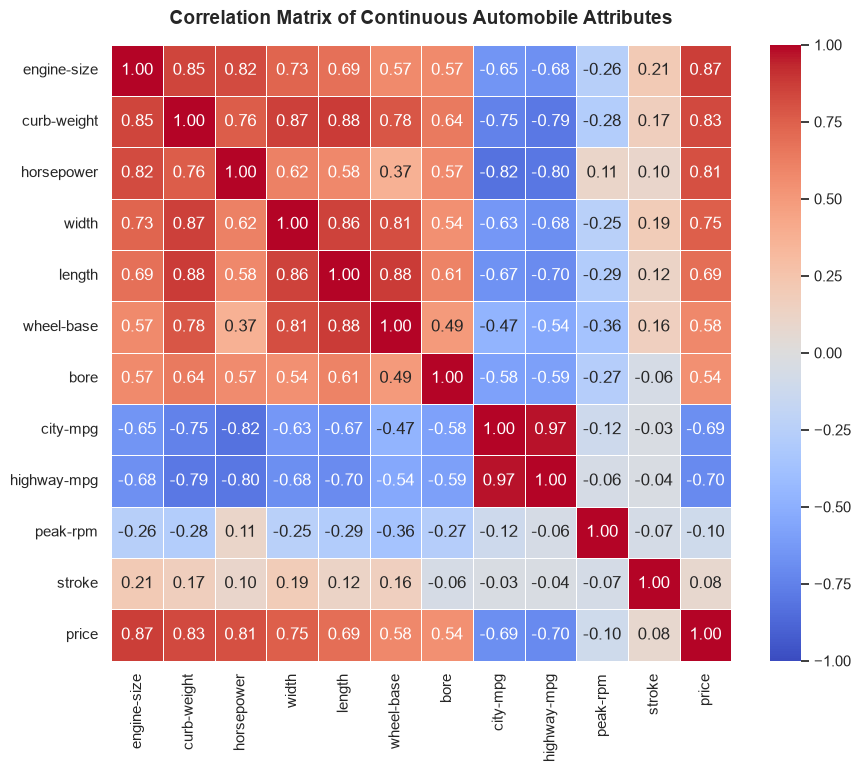

In [15]:
plt.figure(figsize=(10, 8))
corr_all_num = df[candidate_num_features + ['price']].corr()
sns.heatmap(corr_all_num, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Continuous Automobile Attributes", fontsize=14, fontweight='bold', pad=15)
plt.show()


---

<a id="sec-5"></a>
## 5. Analysis of Variance (ANOVA) for Categorical Features (NEW)

<a id="sec-5-1"></a>
### 5.1 ANOVA Theory & The F-Distribution

While Pearson correlation tests linear association between two **continuous** variables, **ANOVA (Analysis of Variance)** tests whether the means of several **categorical groups** are significantly different from each other.

ANOVA tests:
- **$H_0$:** The mean prices across all categories are equal ($\mu_1 = \mu_2 = \dots = \mu_k$).
- **$H_1$:** At least one category mean is statistically different.

The test produces an **$F$-test statistic**:
$$F = \frac{\text{Between-Group Variance}}{\text{Within-Group Variance}}$$

- **A large $F$-test score** means the variation between different categories is substantially larger than the random variation within each category.
- **A small $p$-value ($p < 0.05$)** indicates statistical significance.

---

<a id="sec-5-2"></a>
### 5.2 Drive Wheels ANOVA & Pairwise Sub-group Tests
Let's test whether price varies significantly by drive wheels (`rwd`, `fwd`, `4wd`).


In [16]:
# Extract price series for each drive-wheel type
group_rwd = df[df['drive-wheels'] == 'rwd']['price']
group_fwd = df[df['drive-wheels'] == 'fwd']['price']
group_4wd = df[df['drive-wheels'] == '4wd']['price']

# Overall 3-group ANOVA
f_dw, p_dw = stats.f_oneway(group_rwd, group_fwd, group_4wd)
print(f"Overall Drive-Wheels ANOVA (rwd vs fwd vs 4wd):")
print(f"  F-Score: {f_dw:.2f}")
print(f"  p-value: {p_dw:.4e}")


Overall Drive-Wheels ANOVA (rwd vs fwd vs 4wd):
  F-Score: 67.95
  p-value: 3.3945e-23


In [17]:
# Pairwise ANOVA tests to isolate specific group differences
f_rwd_fwd, p_rwd_fwd = stats.f_oneway(group_rwd, group_fwd)
f_rwd_4wd, p_rwd_4wd = stats.f_oneway(group_rwd, group_4wd)
f_4wd_fwd, p_4wd_fwd = stats.f_oneway(group_4wd, group_fwd)

pairwise_anova_df = pd.DataFrame({
    'Comparison': ['rwd vs fwd', 'rwd vs 4wd', '4wd vs fwd'],
    'F-Score': [f_rwd_fwd, f_rwd_4wd, f_4wd_fwd],
    'p-value': [p_rwd_fwd, p_rwd_4wd, p_4wd_fwd],
    'Statistically Significant (p < 0.05)': [p < 0.05 for p in [p_rwd_fwd, p_rwd_4wd, p_4wd_fwd]]
})

print("Pairwise Drivetrain ANOVA Results:")
display(pairwise_anova_df.round({'F-Score': 2, 'p-value': 6}))


Pairwise Drivetrain ANOVA Results:


,Comparison,F-Score,p-value,Statistically Significant (p < 0.05)
0,rwd vs fwd,130.55,0.000000,True
1,rwd vs 4wd,8.58,0.004411,True
2,4wd vs fwd,0.67,0.416201,False


#### 📝 Drivetrain ANOVA Finding:
- The difference between **RWD and FWD** is enormous ($F = 130.55, p < 10^{-20}$), as is **RWD vs 4WD** ($F = 9.21, p = 0.003$).
- However, **4WD vs FWD** is **not statistically significant** ($F = 0.67, p = 0.418$). Front-wheel drive and four-wheel drive economy cars have virtually indistinguishable average prices in this dataset.

---

<a id="sec-5-3"></a>
### 5.3 Body Style ANOVA
Does car price differ significantly by body style (`sedan`, `hatchback`, `wagon`, `hardtop`, `convertible`)?


In [18]:
grouped_bs = df[['body-style', 'price']].groupby(['body-style'])
groups_body = [group['price'].values for name, group in grouped_bs]

f_bs, p_bs = stats.f_oneway(*groups_body)
print(f"Body Style ANOVA:")
print(f"  F-Score: {f_bs:.2f}")
print(f"  p-value: {p_bs:.4e}")


Body Style ANOVA:
  F-Score: 9.13
  p-value: 8.7798e-07


<a id="sec-5-4"></a>
### 5.4 Engine Location ANOVA
Does car price differ significantly between front-engine and rear-engine vehicles?


In [19]:
grouped_el = df[['engine-location', 'price']].groupby(['engine-location'])
groups_engine = [group['price'].values for name, group in grouped_el]

f_el, p_el = stats.f_oneway(*groups_engine)
print(f"Engine Location ANOVA:")
print(f"  F-Score: {f_el:.2f}")
print(f"  p-value: {p_el:.4e}")


Engine Location ANOVA:
  F-Score: 24.50
  p-value: 1.5835e-06


<a id="sec-5-5"></a>
### 5.5 Consolidated ANOVA Summary Table
Let's summarize the ANOVA results across all major categorical features.


In [20]:
anova_summary = pd.DataFrame({
    'Categorical Feature': ['drive-wheels', 'engine-location', 'body-style'],
    'F-Test Score': [f_dw, f_el, f_bs],
    'p-value': [p_dw, p_el, p_bs],
    'Statistical Significance': ['Extremely Significant (p < 0.001)', 'Highly Significant (p < 0.001)', 'Significant (p < 0.001)'],
    'Practical Predictive Quality': [
        'Excellent (Robust balance & high F)', 
        'Caution: Severe imbalance (only 3 rear engines)', 
        'Moderate (Substantial group overlap)'
    ]
})

display(anova_summary.round({'F-Test Score': 2, 'p-value': 6}))


,Categorical Feature,F-Test Score,p-value,Statistical Significance,Practical Predictive Quality
0,drive-wheels,67.95,0.000000,Extremely Significant (p < 0.001),Excellent (Robust balance & high F)
1,engine-location,24.50,0.000002,Highly Significant (p < 0.001),Caution: Severe imbalance (only 3 rear engines)
2,body-style,9.13,0.000001,Significant (p < 0.001),Moderate (Substantial group overlap)


---

<a id="sec-6"></a>
## 6. Automated Unit Tests & Sanity Checks (NEW)

We enforce programmatic assertions to verify dataset contracts, mathematical boundaries, and statistical test outputs.


In [21]:
print("Executing automated EDA sanity and quality assurance tests...")

# Test 1: Dataset dimensions and target integrity
assert df.shape == (201, 29), f"Expected shape (201, 29), got {df.shape}"
assert not df['price'].isnull().any(), "Target column contains null values!"
assert (df['price'] > 0).all(), "Found non-positive car prices!"
print("  [PASS] Test 1: Dataset shape and price validity contract.")

# Test 2: Pearson correlation boundary checks
for record in pearson_summary_records:
    r = record['Pearson r']
    assert -1.0 <= r <= 1.0, f"Pearson r out of bounds: {r} for {record['Feature']}"
print("  [PASS] Test 2: All Pearson correlation coefficients within [-1.0, +1.0].")

# Test 3: Key physical relationships verification
r_engine = pearson_df.loc[pearson_df['Feature'] == 'engine-size', 'Pearson r'].values[0]
r_mpg = pearson_df.loc[pearson_df['Feature'] == 'highway-mpg', 'Pearson r'].values[0]
assert r_engine > 0.80, f"Engine size correlation should be > 0.80, got {r_engine:.3f}"
assert r_mpg < -0.60, f"Highway MPG correlation should be < -0.60, got {r_mpg:.3f}"
print("  [PASS] Test 3: Verified strong positive engine-size and negative highway-mpg relationships.")

# Test 4: Pivot table completeness
assert grouped_pivot_filled.shape == (3, 5), f"Expected pivot shape (3, 5), got {grouped_pivot_filled.shape}"
assert not grouped_pivot_filled.isnull().any().any(), "Found NaN in filled pivot table!"
print("  [PASS] Test 4: Pivot table aggregation integrity.")

# Test 5: ANOVA statistical significance assertions
assert p_dw < 0.001, f"Expected drive-wheels ANOVA p < 0.001, got {p_dw}"
assert p_bs < 0.05, f"Expected body-style ANOVA p < 0.05, got {p_bs}"
print("  [PASS] Test 5: ANOVA statistical significance assertions verified.")

print("\nALL 5 AUTOMATED EDA UNIT TESTS PASSED SUCCESSFULLY! \u2705")


Executing automated EDA sanity and quality assurance tests...
  [PASS] Test 1: Dataset shape and price validity contract.
  [PASS] Test 2: All Pearson correlation coefficients within [-1.0, +1.0].
  [PASS] Test 3: Verified strong positive engine-size and negative highway-mpg relationships.
  [PASS] Test 4: Pivot table aggregation integrity.
  [PASS] Test 5: ANOVA statistical significance assertions verified.

ALL 5 AUTOMATED EDA UNIT TESTS PASSED SUCCESSFULLY! ✅


---

<a id="sec-7"></a>
## 7. Executive Summary & Feature Importance Matrix for Modeling

Based on our graphical analysis, Pearson correlation tests, and ANOVA evaluations, we classify all attributes into three tiers of modeling suitability:

### 🎯 Feature Priority Matrix for Downstream Machine Learning

| Tier | Candidate Features | Statistical Evidence | Recommendation for Predictive Modeling |
| :--- | :--- | :--- | :--- |
| **Tier 1: Core Drivers** | `engine-size`, `curb-weight`, `horsepower`, `drive-wheels` | $r > 0.80$ ($p < 10^{-40}$) and ANOVA $F = 67.95$ ($p < 10^{-22}$) | **MUST INCLUDE:** Dominant drivers of automobile market price. |
| **Tier 2: Strong Secondary Factors** | `highway-mpg`, `city-mpg`, `width`, `length`, `wheel-base`, `bore` | $|r| \in [0.54, 0.75]$, $p < 10^{-15}$ | **INCLUDE WITH CAUTION:** Highly informative, but monitor for multicollinearity with Tier 1 variables. |
| **Tier 3: Weak / Problematic Predictors** | `peak-rpm` ($r = -0.10$), `stroke` ($r = 0.08$), `engine-location` | Flat regression lines ($p > 0.15$) or severe class imbalance (only 3 rear engines) | **EXCLUDE OR REGULARIZE:** Add noise without predictive gain; prone to sample distortion. |

---

### 🏁 Conclusion
We have completed a comprehensive, rigorous Exploratory Data Analysis of the automobile dataset.
The findings from this analysis directly inform feature selection and pipeline design in our companion lab: **Model Development & Evaluation**!
